In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import io

import networkx as nx
from collections import Counter

import matplotlib.ticker as ticker


In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Key functions

In [3]:


def get_mass_map(filename):
    mass_map = {}
    found_masses_header = False
    
    with open(filename, 'r') as f:
        for line in f:
            clean = line.strip()
            
            # 1. Look for the Masses header
            if "Masses" in clean:
                found_masses_header = True
                continue
            
            if found_masses_header:
                # 2. Split by single space as requested
                parts = line.strip('\n').split(" ")
                # Remove empty strings from list
                data = [p for p in parts if p.strip() != ""]
                
                # 3. Handling logic
                if not data:
                    # If we hit a blank line AFTER collecting masses, STOP.
                    if mass_map: 
                        break
                    continue
                
                # 4. Only record if it's a mass line (starts with digit)
                if data[0].isdigit():
                    try:
                        m_type = int(data[0])
                        m_value = float(data[1])
                        mass_map[m_type] = m_value
                    except (ValueError, IndexError):
                        # If the line structure changes, we've likely left the section
                        if mass_map: break
                else:
                    # If we hit a word (like "Pair" or "Bond"), STOP.
                    if mass_map: 
                        break
    mass_map_out = mass_map
    
    return mass_map_out


def extract_data_4cluster_analysis(nvt_data_file):
    name_wo_ext = nvt_data_file.split('.')[0]
    name_parts = name_wo_ext.split('_')
    hfc_name = name_parts[3]
    num_hfc = int(name_parts[5])
    num_il = int(name_parts[6])
    hfc_mol_ids = np.linspace(1, num_hfc, num_hfc)
    hfc_mol_ids = (hfc_mol_ids).astype(int)
    cation_ids = np.linspace(int(num_hfc + 1), int(num_hfc+num_il), num_il)
    cation_ids = (cation_ids).astype(int)
    anion_ids = np.linspace(int(num_hfc + num_il + 1), int(num_hfc+2*num_il), num_il)
    anion_ids = (anion_ids).astype(int)

    with open(nvt_data_file, 'r') as f:
        lines = f.readlines()
        
    atoms_data = []
    
    current_section = None
    
    for line in lines:
        clean = line.strip()
        if not clean:
            continue
            
        # Detect Section
        if clean == "Atoms" or "Atoms" in clean:
            current_section = "atoms"
            continue
        elif any(header in clean for header in ["Velocities", "Bonds", "Angles"]):
            current_section = None
            continue
        
        # Parse Atoms
        elif current_section == "atoms":
            atoms_data.append(line)

    # 2. Create DataFrame
    cols = ['id', 'mol', 'type', 'q', 'x', 'y', 'z', 'ix', 'iy', 'iz']
    df = pd.read_csv(io.StringIO("".join(atoms_data)), sep=r'\s+', header=None, names=cols)

    mass_map = get_mass_map(nvt_data_file)
    
    # 3. Map the extracted Masses to the 'type' column
    df['mass'] = df['type'].map(mass_map)

    conditions = [
    df['mol'].isin(hfc_mol_ids),
    df['mol'].isin(cation_ids),
    df['mol'].isin(anion_ids)
    ]

    # 3. Define the corresponding values for the new column
    choices = [0, 1, 2]
    
    # 4. Create the new column at the end
    # 'default=-1' helps you spot if any molecule ID wasn't in your lists
    df['specie_id'] = np.select(conditions, choices, default=-1)

    return df
        
def extract_box_from_lammps_data(filepath):
    box = {}

    with open(filepath, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) >= 4:
                if parts[2] == "xlo" and parts[3] == "xhi":
                    box["Lx"] = float(parts[1]) - float(parts[0])
                elif parts[2] == "ylo" and parts[3] == "yhi":
                    box["Ly"] = float(parts[1]) - float(parts[0])
                elif parts[2] == "zlo" and parts[3] == "zhi":
                    box["Lz"] = float(parts[1]) - float(parts[0])

    return np.array([box["Lx"], box["Ly"], box["Lz"]])



def compute_specie_com(df_atoms, box):
    Lx, Ly, Lz = box

    df = df_atoms.copy()

    # unwrap coordinates
    df["xu"] = df["x"] + df["ix"] * Lx
    df["yu"] = df["y"] + df["iy"] * Ly
    df["zu"] = df["z"] + df["iz"] * Lz

    # weighted sums
    df["mx"] = df["mass"] * df["xu"]
    df["my"] = df["mass"] * df["yu"]
    df["mz"] = df["mass"] * df["zu"]

    grouped = df.groupby("mol")

    com_df = grouped.agg(
        x=("mx", "sum"),
        y=("my", "sum"),
        z=("mz", "sum"),
        m_tot=("mass", "sum"),
        specie_id=("specie_id", "first")
    ).reset_index()

    # divide by total mass
    com_df["x"] /= com_df["m_tot"]
    com_df["y"] /= com_df["m_tot"]
    com_df["z"] /= com_df["m_tot"]

    # wrap back into box
    com_df["x"] %= Lx
    com_df["y"] %= Ly
    com_df["z"] %= Lz

    return com_df[["mol", "x", "y", "z", "specie_id"]]



def build_adjacency(coords, box, cutoff):
    """
    Build adjacency matrix using MIC distances.
    """
    N = len(coords)
    adjacency = np.zeros((N, N), dtype=bool)

    for i in range(N):
        dr = coords[i+1:] - coords[i]
        dr -= box * np.round(dr / box)  # MIC
        d = np.linalg.norm(dr, axis=1)

        neighbors = np.where(d <= cutoff)[0] + i + 1
        adjacency[i, neighbors] = True
        adjacency[neighbors, i] = True

    return adjacency


def cluster_analysis_from_com(com_df, box, cutoff):
    """
    Performs cluster analysis on ion CoMs.

    Returns:
        cluster_df : dataframe with columns cluster_size | count
        singlet_mol_ids : list of mol IDs that are singlets
    """

    coords = com_df[["x", "y", "z"]].values

    # Build adjacency (neighbors within cutoff using MIC)
    adjacency = build_adjacency(coords, box, cutoff)

    # Graph → connected components
    G = nx.from_numpy_array(adjacency)
    clusters = list(nx.connected_components(G))

    # Cluster sizes
    sizes = [len(c) for c in clusters]

    # Count how many clusters of each size
    size_counts = Counter(sizes)

    # Build dataframe from size 1 to max size
    max_size = max(size_counts.keys())

    cluster_df = pd.DataFrame({
        "cluster_size": range(1, max_size + 1),
        "count": [size_counts.get(k, 0) for k in range(1, max_size + 1)]
    })

    singlet_indices = [next(iter(c)) for c in clusters if len(c) == 1]
    singlet_mol_ids = com_df.iloc[singlet_indices]["mol"].tolist()

    return cluster_df, singlet_mol_ids



def clustering_analysis_ions(nvt_data_file, cutoff):
    atoms_df = extract_data_4cluster_analysis(nvt_data_file)
    ions_df = atoms_df[atoms_df["specie_id"].isin([1, 2])].copy()
    box_ = extract_box_from_lammps_data(nvt_data_file)
    com_ions_df = compute_specie_com(ions_df, box_)
    
    clust_df, singlets = cluster_analysis_from_com(com_ions_df, box_, cutoff)

    return clust_df, singlets, com_ions_df, atoms_df
    



In [4]:

def get_hfc_com(nvt_data_file):
    atoms_df = extract_data_4cluster_analysis(nvt_data_file)
    hfc_df = atoms_df[atoms_df["specie_id"].isin([0])].copy()
    box_ = extract_box_from_lammps_data(nvt_data_file)
    com_hfc_df = compute_specie_com(hfc_df, box_)
    return com_hfc_df



def mic_distance(target_coords, coords, box):
    """
    Computes MIC distance between a single point (target_coords)
    and an array of points (coords) using periodic boundary conditions.
    
    target_coords: array-like, shape (3,)
    coords: array-like, shape (N,3)
    box: array-like, [Lx, Ly, Lz]
    
    Returns: distances (N,)
    """
    dr = coords - target_coords
    dr -= box * np.round(dr / box)  # MIC
    dist = np.linalg.norm(dr, axis=1)
    return dist



def find_neighbors(target_com_df, nvt_data_file, cutoff):
    target_coords = target_com_df.iloc[0][["x","y","z"]].values
    hfc_com_df = get_hfc_com(nvt_data_file)
    coords = hfc_com_df[["x","y","z"]].values
    box = extract_box_from_lammps_data(nvt_data_file)
    distances = mic_distance(target_coords, coords, box)
    
    mask = distances <= cutoff
    neighbor_mols = hfc_com_df.loc[mask, "mol"].tolist()
    neighbor_df = hfc_com_df.loc[mask].copy()
    neighbor_df["distance_to_target"] = distances[mask]
    
    return neighbor_mols, neighbor_df, box


def extract_atoms_for_visualization(atom_df, target_com_df, neighbor_com_df):
    """
    Extract all atoms belonging to the target ion and all neighboring molecules.
    
    Returns a dataframe with atoms only for visualization.
    """
    # Get Mol IDs
    target_mol = target_com_df.iloc[0]["mol"]
    neighbor_mols = neighbor_com_df["mol"].tolist()
    
    mols_to_extract = [target_mol] + neighbor_mols
    
    # Subset atom dataframe
    atoms_subset = atom_df[atom_df["mol"].isin(mols_to_extract)].copy()
    
    return atoms_subset



def assign_atomic_symbols(atoms_df):
    """
    Assign atomic symbols based on mass (rounded to nearest integer).
    """
    atoms_df = atoms_df.copy()
    atoms_df["mass_round"] = atoms_df["mass"].round().astype(int)
    atoms_df["element"] = atoms_df["mass_round"].map(mass_to_symbol)
    
    # Fallback for missing masses
    atoms_df["element"] = atoms_df["element"].fillna("X")
    
    return atoms_df

def write_xyz_ovito(atoms_subset_df, filename="selection.xyz"):
    """
    Write XYZ file for OVITO using the correct atomic symbols.
    Uses x, y, z as-is (no unwrapping).
    """
    n_atoms = len(atoms_subset_df)
    with open(filename, "w") as f:
        f.write(f"{n_atoms}\n")
        f.write("Target ion + HFC neighbors\n")
        for i, row in atoms_subset_df.iterrows():
            elem = row["element"]
            x, y, z = row["x"], row["y"], row["z"]  # use original coords
            f.write(f"{elem} {x:.6f} {y:.6f} {z:.6f}\n")
    return filename


def make_molecule_whole(atom_df, box):
    """
    Given a dataframe of atoms for a single molecule with wrapped coordinates,
    adjust coordinates to make the molecule whole across periodic boundaries
    while keeping the original center of mass fixed.

    atom_df: DataFrame with columns ['x', 'y', 'z', 'mass']
    box: np.array([Lx, Ly, Lz])
    """
    df = atom_df.copy()
    Lx, Ly, Lz = box
    box_vec = np.array([Lx, Ly, Lz])
    
    # Original CoM
    m_total = df['mass'].sum()
    CoM_orig = np.array([(df['x']*df['mass']).sum()/m_total,
                         (df['y']*df['mass']).sum()/m_total,
                         (df['z']*df['mass']).sum()/m_total])
    
    # Start unwrapping relative to first atom
    ref = df.iloc[0][['x','y','z']].values
    new_coords = []
    for i, row in df.iterrows():
        pos = row[['x','y','z']].values
        delta = pos - ref
        
        # Apply MIC for each coordinate
        delta -= box_vec * np.round(delta / box_vec)
        
        new_pos = ref + delta
        new_coords.append(new_pos)
    
    new_coords = np.array(new_coords)
    
    # New CoM
    CoM_new = np.average(new_coords, axis=0, weights=df['mass'].values)
    
    # Shift to keep original CoM fixed
    shift = CoM_orig - CoM_new
    new_coords += shift
    
    # Assign back
    df[['x','y','z']] = new_coords
    return df


def write_xyz_detailed(atoms_df, target_mol_id, filename="xyz_detailed.xyz"):
    """
    Write XYZ file for OVITO:
      - HFC atoms = 0
      - Target ion atoms = 1,2,3... per atom type
    """
    df = atoms_df.copy()
    
    # Determine unique atom types in the ion
    ion_atoms = df[df['mol'] == target_mol_id]
    unique_types = ion_atoms['type'].unique()
    type_mapping = {t: i+1 for i, t in enumerate(unique_types)}  # start from 1
    
    n_atoms = len(df)
    with open(filename, "w") as f:
        f.write(f"{n_atoms}\n")
        f.write("HFC = 0, Ion atoms numbered 1,2,... per atom type\n")
        for _, row in df.iterrows():
            x, y, z = row["x"], row["y"], row["z"]  # can switch to unwrapped if needed
            elem = row["element"]
            if row['mol'] == target_mol_id:
                mol_type = type_mapping[row['type']]
            else:
                mol_type = 0
            f.write(f"{elem} {x:.6f} {y:.6f} {z:.6f} {mol_type}\n")
    
    return filename




# Generation of PDB of fully isolated ions surrounded with HFC molecules

In [5]:
%%time

# test_input = "restart_NVTComplete_01_R134a_emimtfsi_1294_128_656_reshape_HFD.data"
# cluster_df_test, singlet_mols, com_ions_df, atoms_df = clustering_analysis_ions(test_input, 9.1) # 9.3

# Comment the two lines above and uncomment the two lines below to get PDB for R32 around IL
test_input = "restart_NVTComplete_02_R32_emimtfsi_2048_86_1653_reshape_HFD.data"
cluster_df_test, singlet_mols, com_ions_df, atoms_df = clustering_analysis_ions(test_input, 8.9) # 9.2


CPU times: total: 141 ms
Wall time: 485 ms


In [6]:
cluster_df_test.head()

,cluster_size,count
0,1,3
1,2,3
2,3,2
3,4,0
4,5,1


In [7]:

hfc_com_test = get_hfc_com(test_input)
print(len(hfc_com_test))
hfc_com_test.head()


2048


,mol,x,y,z,specie_id
0,1,4.355843,2.608382,39.995012,0
1,2,40.490337,20.915872,1.616037,0
2,3,40.967374,18.285426,44.555366,0
3,4,19.561698,19.020535,16.196493,0
4,5,31.332880,42.925753,42.902316,0


In [8]:
singlet_mols

[2070, 2119, 2209]

In [9]:
target_mol_id = singlet_mols[-1]  # pick the first singlet for cation (specie_id == 1) and the last for anion (specie_id == 2)

# Subset the CoM dataframe for that ion
target_com_df = com_ions_df[com_ions_df["mol"] == target_mol_id].copy()

In [10]:
target_com_df

,mol,x,y,z,specie_id
160,2209,32.431212,42.275799,54.392313,2


In [11]:

#hfc_neighbor_mols, hfc_neighbor_df, box_ = find_neighbors(target_com_df, test_input, 8.1) # This is for R134a around EMIM
#hfc_neighbor_mols, hfc_neighbor_df, box_ = find_neighbors(target_com_df, test_input, 8.2) # This is for R134a around TFSI

#hfc_neighbor_mols, hfc_neighbor_df, box_ = find_neighbors(target_com_df, test_input, 7.5) # uncomment for R32 around EMIM
hfc_neighbor_mols, hfc_neighbor_df, box_ = find_neighbors(target_com_df, test_input, 7.6) # uncomment for R32 around TFSI
print(len(hfc_neighbor_df))


20


In [12]:
# 15, 14, 18, 20

In [13]:
hfc_neighbor_df.head()

,mol,x,y,z,specie_id,distance_to_target
33,34,36.426282,40.603184,56.226145,0,4.703314
59,60,35.429874,37.855378,50.222331,0,6.776492
131,132,35.512462,42.094758,50.698656,0,4.813520
278,279,31.424865,48.235085,56.739990,0,6.483626
516,517,27.210465,42.163727,55.781968,0,5.403693


In [14]:
mass_to_symbol = {
    1: "H",
    12: "C",
    14: "N",
    16: "O",
    19: "F",
    32: "S",
    35: "Cl"
}

In [15]:

atoms_for_viz = extract_atoms_for_visualization(atoms_df, target_com_df, hfc_neighbor_df)

print(f"Number of atoms extracted: {len(atoms_for_viz)}")


Number of atoms extracted: 115


In [16]:
atoms_for_viz.head()

,id,mol,type,q,x,y,z,ix,iy,iz,mass,specie_id
5653,6938,1388,3,0.048050,29.434407,43.452672,51.326064,-6,1,4,1.008,0
5655,6936,1388,1,0.405467,29.017085,43.225005,50.310957,-6,1,4,12.011,0
5658,6940,1388,3,0.048050,27.983765,42.937124,50.304423,-6,1,4,1.008,0
5660,9573,1915,3,0.048050,27.269261,38.784939,50.704239,-6,0,2,1.008,0
5661,9572,1915,2,-0.250783,26.265927,40.426794,50.403082,-6,0,2,18.998,0


In [17]:
atoms_for_viz = make_molecule_whole(atoms_for_viz, box_)

In [18]:
atoms_for_viz.head()

,id,mol,type,q,x,y,z,ix,iy,iz,mass,specie_id
5653,6938,1388,3,0.048050,29.434407,43.452672,43.595777,-6,1,4,1.008,0
5655,6936,1388,1,0.405467,29.017085,43.225005,42.580670,-6,1,4,12.011,0
5658,6940,1388,3,0.048050,27.983765,42.937124,42.574136,-6,1,4,1.008,0
5660,9573,1915,3,0.048050,27.269261,38.784939,42.973952,-6,0,2,1.008,0
5661,9572,1915,2,-0.250783,26.265927,40.426794,42.672796,-6,0,2,18.998,0


In [19]:

atoms_for_viz = assign_atomic_symbols(atoms_for_viz)

xyz_file = write_xyz_detailed(atoms_for_viz, target_mol_id, "target_with_neighbors_whole_iondiff_det.xyz")

print(f"XYZ file saved to: {xyz_file}")


XYZ file saved to: target_with_neighbors_whole_iondiff_det.xyz


In [20]:
atoms_for_viz.head()

,id,mol,type,q,x,y,z,ix,iy,iz,mass,specie_id,mass_round,element
5653,6938,1388,3,0.048050,29.434407,43.452672,43.595777,-6,1,4,1.008,0,1,H
5655,6936,1388,1,0.405467,29.017085,43.225005,42.580670,-6,1,4,12.011,0,12,C
5658,6940,1388,3,0.048050,27.983765,42.937124,42.574136,-6,1,4,1.008,0,1,H
5660,9573,1915,3,0.048050,27.269261,38.784939,42.973952,-6,0,2,1.008,0,1,H
5661,9572,1915,2,-0.250783,26.265927,40.426794,42.672796,-6,0,2,18.998,0,19,F


In [21]:

def write_pdb_from_df(df, target_mol_id, filename="structure.pdb"):
    
    df = df.copy()
    
    # Assign residue name
    df["resname"] = df["mol"].apply(
        lambda m: "ION" if m == target_mol_id else "HFC"
    )
    
    # Renumber residues sequentially (VMD prefers this)
    unique_mols = df["mol"].unique()
    mol_to_resid = {mol: i+1 for i, mol in enumerate(unique_mols)}
    df["resid"] = df["mol"].map(mol_to_resid)
    
    # Atom names (C1, H2, F3 etc within each molecule)
    df["atom_name"] = ""
    for mol, group in df.groupby("mol"):
        for i, idx in enumerate(group.index, start=1):
            elem = df.loc[idx, "element"]
            df.loc[idx, "atom_name"] = f"{elem}{i}"
    
    # Write PDB
    with open(filename, "w") as f:
        atom_serial = 1
        for _, row in df.iterrows():
            f.write(
                f"ATOM  {atom_serial:5d} "
                f"{row['atom_name']:<4s} "
                f"{row['resname']:>3s} "
                f"A{row['resid']:4d}    "
                f"{row['x']:8.3f}"
                f"{row['y']:8.3f}"
                f"{row['z']:8.3f}"
                f"  1.00  0.00          "
                f"{row['element']:>2s}\n"
            )
            atom_serial += 1
        
        f.write("END\n")
    
    print(f"PDB written to: {filename}")



In [22]:


#write_pdb_from_df(atoms_for_viz, target_mol_id, filename="R134a_around_Isolated_EMIM.pdb")   #uncomment for R134a around EMIM
#write_pdb_from_df(atoms_for_viz, target_mol_id, filename="R134a_around_Isolated_TFSI.pdb") #uncomment for R134a around TFSI
#write_pdb_from_df(atoms_for_viz, target_mol_id, filename="R32_around_Isolated_EMIM.pdb")  #uncomment for R32 around EMIM
write_pdb_from_df(atoms_for_viz, target_mol_id, filename="R32_around_Isolated_TFSI.pdb")  #uncomment for R32 around TFSI


PDB written to: R32_around_Isolated_TFSI.pdb


# Cluster Analysis and Plots

In [23]:

# 1. Global Styling
plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 16,
    "axes.linewidth": 1.5
})

def draw_cluster_row(subfig, avg_df, hfc_comp, hfc_name, is_last_row, color_hex='#2ca02c'):
    """
    Internal function to draw a single row of the combined plot.
    """
    # Identify Data Regions
    data_points = avg_df[avg_df['avg_count'] > 0].sort_values('cluster_size')
    active_sizes = data_points['cluster_size'].tolist()
    
    if not active_sizes:
        return

    has_break = False
    # Break logic
    if len(active_sizes) > 1:
        gaps = np.diff(active_sizes)
        if np.max(gaps) >= 100:
            max_gap_idx = np.argmax(gaps)
            left_end = active_sizes[max_gap_idx] + 20
            right_start = active_sizes[max_gap_idx + 1] - 20
            has_break = True
    elif len(active_sizes) == 1 and active_sizes[0] > 100:
        left_end = 20
        right_start = active_sizes[0] - 20
        has_break = True

    # Setup Axes within the subfigure
    if has_break:
        axes = subfig.subplots(1, 2, sharey=True, gridspec_kw={'wspace': 0.15})
        ax1, ax2 = axes
        ax1.set_xlim(left=0, right=left_end)
        ax2.set_xlim(left=right_start, right=max(active_sizes) + 20)
        
        # Style break
        ax1.spines['right'].set_visible(False)
        ax1.spines['top'].set_visible(False)
        ax2.spines['left'].set_visible(False)
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)
        ax2.tick_params(axis='y', which='both', left=False)
        
        # Break markers (Bottom only)
        d = .025 
        kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False, lw=1)
        ax1.plot((1-d, 1+d), (-d, +d), **kwargs)
        kwargs.update(transform=ax2.transAxes)
        ax2.plot((-d, +d), (-d, +d), **kwargs)
    else:
        ax1 = subfig.subplots(1, 1)
        axes = [ax1]
        ax1.spines['top'].set_visible(False)
        ax1.spines['right'].set_visible(False)

    # Plotting loop
    for ax in axes:
        ax.set_yscale('log')
        ax.bar(avg_df['cluster_size'], avg_df['avg_count'], 
               width=0.8, color=color_hex, edgecolor=color_hex, linewidth=1)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=5))
        ax.tick_params(axis='both', which='major', labelsize=16.5)
        ax.tick_params(axis='both', which='minor', labelsize=0)
        ax.grid(axis='y', which='major', linestyle='--', alpha=0.3)
        ax.grid(axis='x', visible=False)

    # Labels for this specific row
    # Concentration label
    subfig.text(0.5, 0.70, rf"$x_{{\mathrm{{{hfc_name}}}}} = {hfc_comp}$", 
                ha='center', fontsize=18)
    
    # Y-axis label (only on the left-most axis)
    axes[0].set_ylabel(r'$\langle N_n \rangle$', fontsize=20, fontweight='bold')
    
    # X-axis label (only on the last row)
    if is_last_row:
        subfig.text(0.5, -0.15, 'Cluster Size ($n$)', ha='center', fontsize=20)




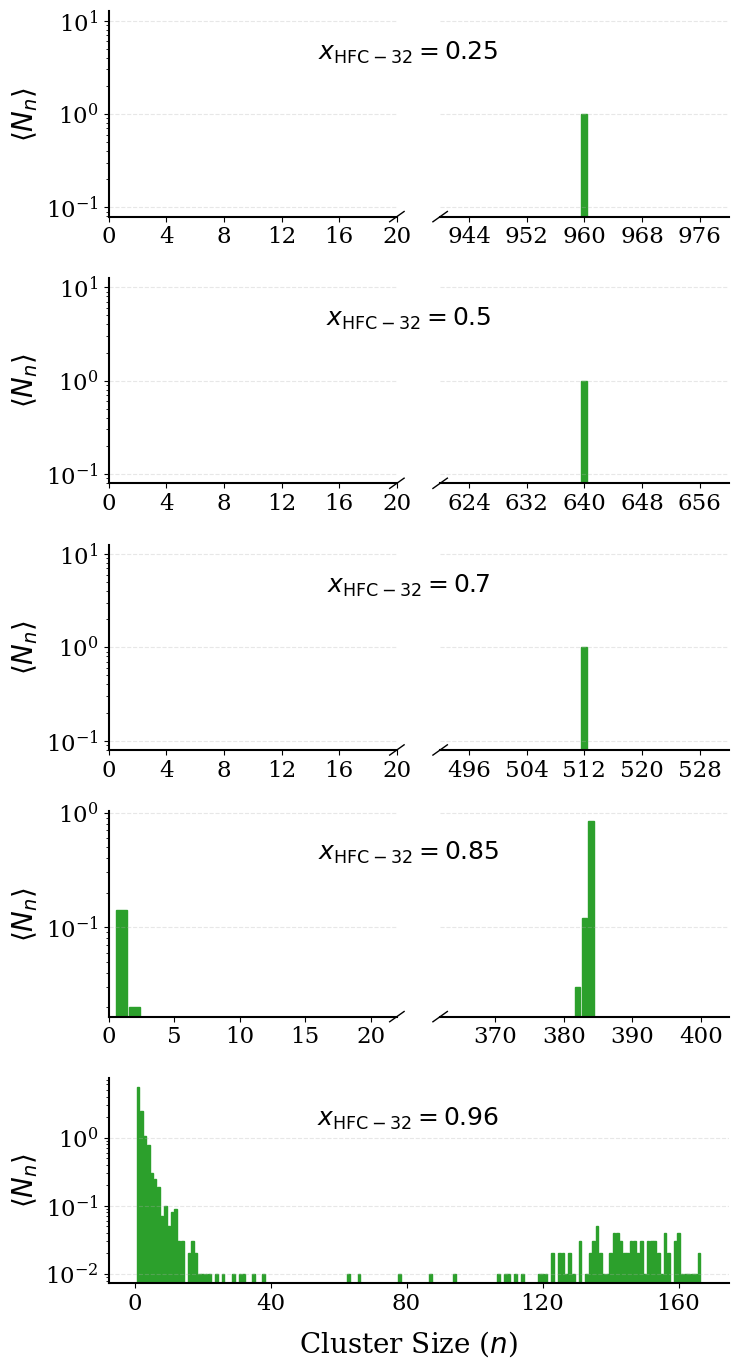

In [28]:

# Load labels and compositions
R32_labels_dist = pd.read_excel("Experimental_Data_All.xlsx", sheet_name='Labels_Cluster_R32')
R32_clust_labels = R32_labels_dist.iloc[:, 0].tolist()
R32_clust_comps = R32_labels_dist.iloc[:, 2].tolist()

n_rows = len(R32_clust_labels)

# Create Master Figure (Total height is 8/3 * number of plots)
fig = plt.figure(figsize=(8, (8/3) * n_rows))
# Create subfigures for each row
sfigs = fig.subfigures(n_rows, 1)

for i, name in enumerate(R32_clust_labels):
    try:
        avg_df = pd.read_csv(f"NVTComplete_02_{name}_averaged_clust_df.csv")
        is_last = (i == n_rows - 1)
        
        # Handle single vs multiple subfigure return types
        current_sfig = sfigs[i] if n_rows > 1 else sfigs
        
        draw_cluster_row(current_sfig, avg_df, R32_clust_comps[i], 'HFC-32', is_last)
    except FileNotFoundError:
        print(f"File not found: NVTComplete_02_{name}_averaged_clust_df.csv")

# Final saving
plt.savefig("Combined_R32_Cluster_Analysis_Distributions.png", dpi=300, bbox_inches='tight')
plt.show()


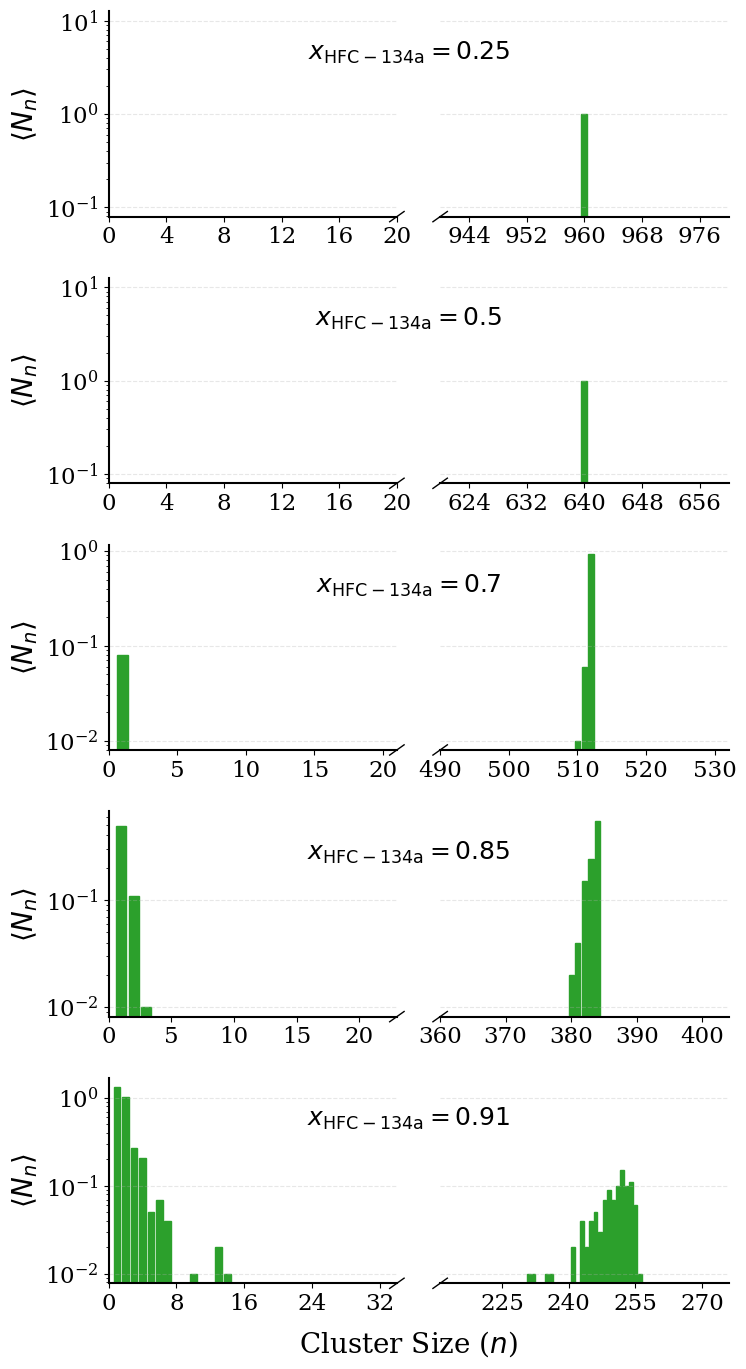

In [29]:
# Load labels and compositions
R134a_labels_dist = pd.read_excel("Experimental_Data_All.xlsx", sheet_name='Labels_Cluster_R134a')
R134a_clust_labels = R134a_labels_dist.iloc[:, 0].tolist()
R134a_clust_comps = R134a_labels_dist.iloc[:, 2].tolist()

n_rows = len(R134a_clust_labels)

# Create Master Figure (Total height is 8/3 * number of plots)
fig = plt.figure(figsize=(8, (8/3) * n_rows))
# Create subfigures for each row
sfigs = fig.subfigures(n_rows, 1)

for i, name in enumerate(R134a_clust_labels):
    try:
        avg_df = pd.read_csv(f"NVTComplete_02_{name}_averaged_clust_df.csv")
        is_last = (i == n_rows - 1)
        
        # Handle single vs multiple subfigure return types
        current_sfig = sfigs[i] if n_rows > 1 else sfigs
        
        draw_cluster_row(current_sfig, avg_df, R134a_clust_comps[i], 'HFC-134a', is_last)
    except FileNotFoundError:
        print(f"File not found: NVTComplete_02_{name}_averaged_clust_df.csv")

# Final saving
plt.savefig("Combined_R134a_Cluster_Analysis_Distributions.png", dpi=300, bbox_inches='tight')
plt.show()
